In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob

In [2]:
df_umap_coords = pd.read_csv("/gpfs/home/qcf21tku/test.umap_out.tsv", sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,3300060270_Ga0586924_0000079,-5.466690,12.560127,3300060270
1,3300060270_Ga0586924_0000088,-5.491396,12.564982,3300060270
2,3300060270_Ga0586924_0000194,-5.444559,12.570843,3300060270
3,3300060270_Ga0586924_0000254,-5.476004,12.564417,3300060270
4,3300060270_Ga0586924_0000281,-5.421247,12.535932,3300060270


In [3]:
bins = pd.read_csv("/gpfs/home/qcf21tku/test.mcl_out.bins.tsv", sep = '\t')

counts = bins.groupby('mcl_bin_id').count()

counts = counts.to_dict()['contig_id']

In [4]:
vamb_bins = pd.read_csv(
    "/gpfs/home/qcf21tku/scratch/E04_1/vamb_multi/vae_clusters.tsv", 
    sep = '\t', 
    names = ['vamb_bin_id', 'contig_id']
)

vcounts = vamb_bins.groupby('vamb_bin_id').count()

vcounts = vcounts.to_dict()['contig_id']

In [109]:
def make_mbat_bin(metabat_path):
    df_tmp = pd.read_csv(metabat_path, names = ['contig_id'])
    df_tmp['sample'] = df_tmp.contig_id.apply(lambda x: x.split("_")[0])
    df_tmp['contig_id'] = df_tmp.contig_id.apply(lambda x: "_".join(x.split("_")[1:]))
    df_tmp['mbat_bin_id'] = "mbat." + metabat_path.split(".")[-3]
    return df_tmp

metabat = pd.concat((make_mbat_bin(f"/gpfs/home/qcf21tku/scratch/E04_1/metabat_v1/mbat.{f}.contigs.txt") for f in ["5", "6", "10"]))

metabat.head()

,contig_id,sample,mbat_bin_id
0,Ga0586924_0016935,3300060270,mbat.5
1,Ga0586924_0018999,3300060270,mbat.5
2,Ga0586924_0019146,3300060270,mbat.5
3,Ga0586924_0020906,3300060270,mbat.5
4,Ga0586924_0021773,3300060270,mbat.5


In [110]:
df = pd.merge(
    bins,
    df_umap_coords,
    left_on = 'contig_id', 
    right_index = True, 
)

df = df[['sample', 'contig_id_y', 'umap_0', 'umap_1', 'mcl_bin_id']].rename(columns = {'contig_id_y':'contig_id'})
df['mcl_bin_id'] = df.mcl_bin_id.apply(lambda x: 'none' if counts[x] < 75 else x)

df = pd.merge(
    df, 
    vamb_bins, 
    on = 'contig_id'
)

df['vamb_bin_id'] = df.vamb_bin_id.apply(lambda x: 'none' if vcounts[x] < 75 else x)

df['contig_id'] = df.contig_id.apply(lambda x: "_".join(x.split("_")[1:]))

df = pd.merge(
    df, 
    metabat, 
    on = ['sample', 'contig_id'],
    how = 'left'
).fillna('none')

print(df.shape)
df.head()

(37779, 7)


,sample,contig_id,umap_0,umap_1,mcl_bin_id,vamb_bin_id,mbat_bin_id
0,3300060270,Ga0586924_0127985,-1.806774,13.210325,mcl.1,none,none
1,3300060270,Ga0586924_0139587,-2.847662,13.150806,mcl.1,none,mbat.5
2,3300060270,Ga0586924_0027588,1.834912,8.035063,mcl.1,none,none
3,3300060270,Ga0586924_0088829,-1.787192,13.346464,mcl.1,none,none
4,3300060270,Ga0586924_0089295,-2.374992,12.935068,mcl.1,none,none


In [112]:
! cat /gpfs/home/qcf21tku/scratch/E04_1/metabat_v1/bins_checked/eukcc.csv

bin	completeness	contamination	ncbi_lng
E04_1_euks.6.fa	46.4	7.4	1-131567-2759-33090-3041-1035538-13792-41873-38832
E04_1_euks.5.fa	10.81	1.89	1-131567-2759-2698737-33630-877183-2605696
E04_1_euks.10.fa	63.6	7.0	1-131567-2759-33090-3041-1035538-13792-41873-38832


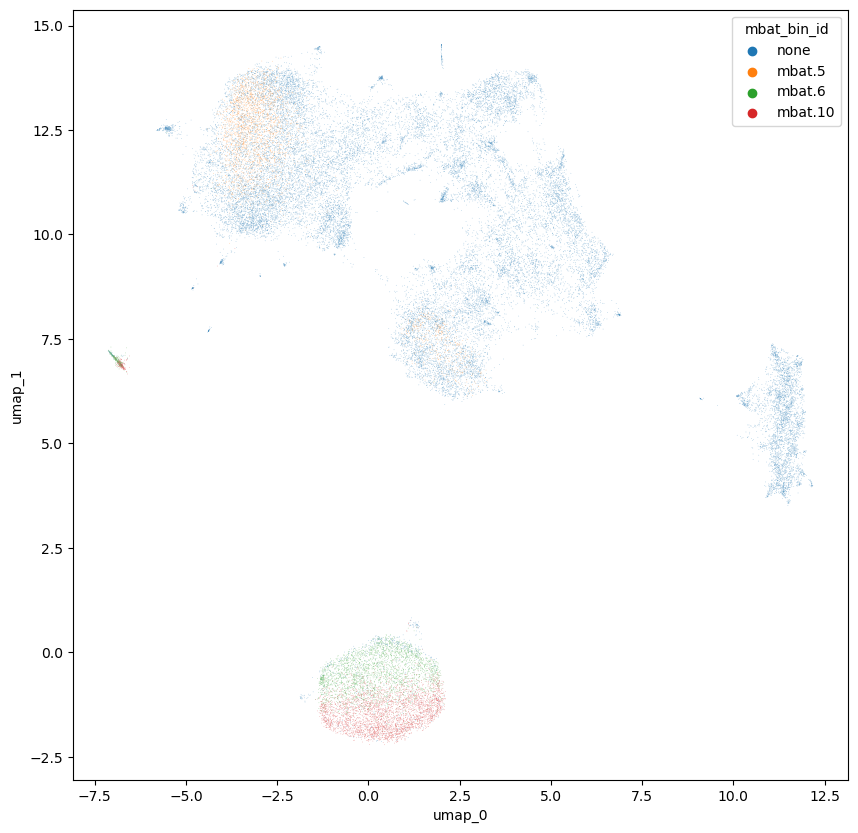

In [111]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'mbat_bin_id', 
    alpha = 0.5
)

In [23]:
def make_large_df(taxo_path):
    df_tmp = pd.read_csv(taxo_path, sep = '\t')
    df_tmp['sample'] = taxo_path.split("/")[-2]

    df_tmp = pd.merge(
        df, 
        df_tmp, 
        on = ['sample', 'contig_id'], 
        how = 'inner'
    )
    return df_tmp

df2 = pd.concat((
    make_large_df(f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{f}/{f}.faa.mms2lca")
    for f in ["3300060026", "3300060027", "3300060270"]
))

In [117]:
df3 = df2[
df2.name.isin(df2[
    (df2.superkingdom == "Eukaryota") #& 
    #(np.abs(df2.umap_1 - 12) < 2) & 
    #(np.abs(df2.umap_0 - 3.5) < 1.5)
][
    ['name', 'sample']
].groupby('name').count().sort_values(
    'sample', ascending = False
).head(25).index)
]

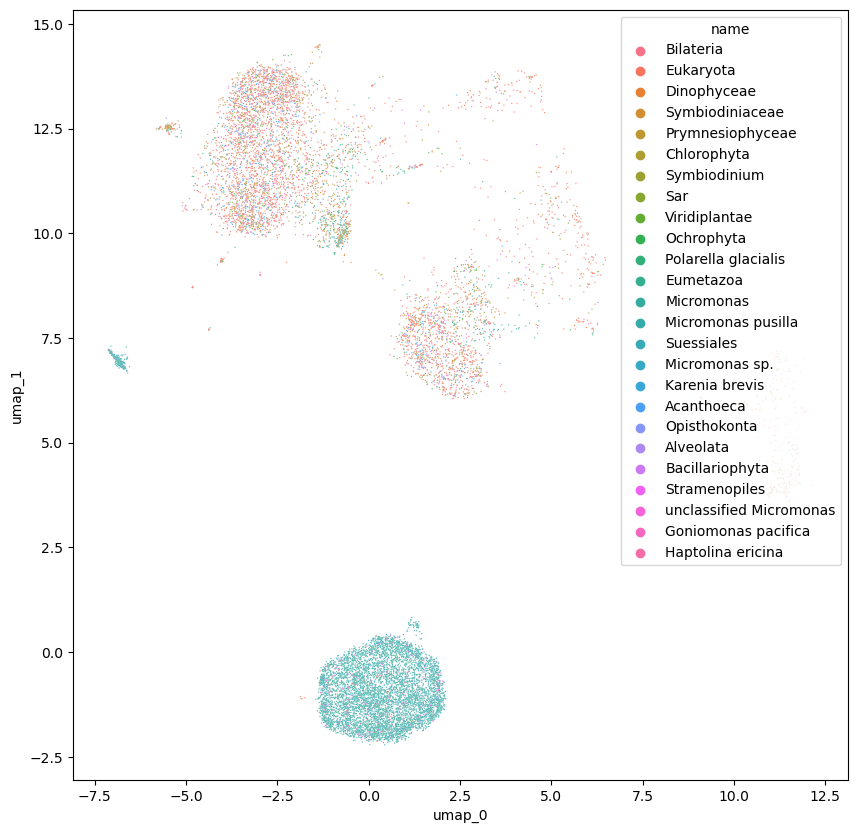

In [118]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df3, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.85, 
    hue = 'name', 
    alpha = 0.95
)

In [123]:
df2[
    #(df2.superkingdom == "Eukaryota") & 
    (np.abs(df2.umap_1 - 12) < 2) & 
    (np.abs(df2.umap_0 - 3.5) < 2)
][
    ['name', 'sample']
].groupby('name').count().sort_values(
    'sample', ascending = False
).head(25)

,sample
name,
Eukaryota,152
Bacteria,150
uncultured Caudovirales phage,144
cellular organisms,138
unclassified Prasinovirus,124
Micromonas pusilla virus 12T,87
Prasinovirus,81
Euryarchaeota archaeon,56
uncultured Mediterranean phage,51


In [124]:
df2[
    (df2.umap_0 > 10)
][
    ['name', 'sample']
].groupby('name').count().sort_values(
    'sample', ascending = False
).head(25)

,sample
name,
Bacteria,169
cellular organisms,126
Eukaryota,123
uncultured Mediterranean phage,69
Planctomycetota bacterium,46
Prokaryotic dsDNA virus sp.,44
uncultured Caudovirales phage,35
Candidatus Poribacteria bacterium,33
Euryarchaeota archaeon,32
